In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from unidecode import unidecode
import warnings

warnings.filterwarnings('ignore')

# Set visual aesthetics for our dark/clean theme
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("✅ Libraries imported successfully!")

✅ Libraries imported successfully!


In [3]:
DATA_DIR = r'C:\Users\anike\Desktop\Data Analyst Projects\Project 1\Data Set'

# Load all 9 CSVs
customers = pd.read_csv(os.path.join(DATA_DIR, 'olist_customers_dataset.csv'))
orders = pd.read_csv(os.path.join(DATA_DIR, 'olist_orders_dataset.csv'))
order_items = pd.read_csv(os.path.join(DATA_DIR, 'olist_order_items_dataset.csv'))
payments = pd.read_csv(os.path.join(DATA_DIR, 'olist_order_payments_dataset.csv'))
reviews = pd.read_csv(os.path.join(DATA_DIR, 'olist_order_reviews_dataset.csv'))
products = pd.read_csv(os.path.join(DATA_DIR, 'olist_products_dataset.csv'))
sellers = pd.read_csv(os.path.join(DATA_DIR, 'olist_sellers_dataset.csv'))
geolocation = pd.read_csv(os.path.join(DATA_DIR, 'olist_geolocation_dataset.csv'))
translations = pd.read_csv(os.path.join(DATA_DIR, 'product_category_name_translation.csv'))

# Display shapes
datasets = {
    "Customers": customers,
    "Orders": orders,
    "Order Items": order_items,
    "Payments": payments,
    "Reviews": reviews,
    "Products": products,
    "Sellers": sellers,
    "Geolocation": geolocation,
    "Translations": translations
}

for name, df in datasets.items():
    print(f"📁 {name:<15}: {df.shape[0]:>8,} rows | {df.shape[1]} columns")

📁 Customers      :   99,441 rows | 5 columns
📁 Orders         :   99,441 rows | 8 columns
📁 Order Items    :  112,650 rows | 7 columns
📁 Payments       :  103,886 rows | 5 columns
📁 Reviews        :   99,224 rows | 7 columns
📁 Products       :   32,951 rows | 9 columns
📁 Sellers        :    3,095 rows | 4 columns
📁 Geolocation    : 1,000,163 rows | 5 columns
📁 Translations   :       71 rows | 2 columns


In [4]:
# 1. Fix column name typos
products.rename(columns={
    'product_name_lenght': 'product_name_length',
    'product_description_lenght': 'product_description_length'
}, inplace=True)

# 2. Merge with English translations
products = products.merge(
    translations, 
    on='product_category_name', 
    how='left'
)

# 3. Handle missing categories
products['product_category_name_english'] = products['product_category_name_english'].fillna('unknown')

# 4. Fill missing numeric physical attributes with median values
numeric_cols = ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
for col in numeric_cols:
    products[col] = products[col].fillna(products[col].median())

# 5. Calculate Product Volume in cm^3
products['product_volume_cm3'] = (
    products['product_length_cm'] * 
    products['product_height_cm'] * 
    products['product_width_cm']
)

print(f"✅ Products cleaned! Total products: {len(products):,}")
print(f"Missing English categories: {products['product_category_name_english'].isnull().sum()}")
products[['product_id', 'product_category_name_english', 'product_weight_g', 'product_volume_cm3']].head(3)

✅ Products cleaned! Total products: 32,951
Missing English categories: 0


,product_id,product_category_name_english,product_weight_g,product_volume_cm3
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumery,225.0,2240.0
1,3aa071139cb16b67ca9e5dea641aaa2f,art,1000.0,10800.0
2,96bd76ec8810374ed1b65e291975717f,sports_leisure,154.0,2430.0


In [5]:
# 1. Define city normalization function (strips accents, lowercase -> Title Case)
def normalize_text(text):
    if pd.isna(text):
        return text
    # unidecode removes accents: 'são paulo' -> 'sao paulo'
    return unidecode(str(text)).strip().lower().title()

# 2. Normalize city names across Geolocation, Customers, and Sellers
print("Normalizing city names across tables...")
geolocation['geolocation_city'] = geolocation['geolocation_city'].apply(normalize_text)
customers['customer_city'] = customers['customer_city'].apply(normalize_text)
sellers['seller_city'] = sellers['seller_city'].apply(normalize_text)

# 3. Deduplicate Geolocation: Aggregate to 1 unique row per zip_code_prefix
# Using median for coordinates (robust against outlier GPS points)
geo_clean = geolocation.groupby('geolocation_zip_code_prefix').agg({
    'geolocation_lat': 'median',
    'geolocation_lng': 'median',
    'geolocation_city': 'first',
    'geolocation_state': 'first'
}).reset_index()

# Rename columns to standard dimension format
geo_clean.rename(columns={
    'geolocation_zip_code_prefix': 'zip_code_prefix',
    'geolocation_lat': 'latitude',
    'geolocation_lng': 'longitude',
    'geolocation_city': 'city',
    'geolocation_state': 'state'
}, inplace=True)

print(f"✅ Geolocation deduplicated: {len(geolocation):,} rows ➡️ {len(geo_clean):,} unique zip codes!")
geo_clean.head(3)

Normalizing city names across tables...
✅ Geolocation deduplicated: 1,000,163 rows ➡️ 19,015 unique zip codes!


,zip_code_prefix,latitude,longitude,city,state
0,1001,-23.550381,-46.634027,Sao Paulo,SP
1,1002,-23.548551,-46.635072,Sao Paulo,SP
2,1003,-23.548977,-46.635313,Sao Paulo,SP


In [6]:
# 1. Convert all date columns to datetime
date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

# 2. Detect & Remove Temporal Anomalies (Delivered before Purchased)
invalid_delivery_mask = (
    orders['order_delivered_customer_date'].notnull() & 
    (orders['order_delivered_customer_date'] < orders['order_purchase_timestamp'])
)
anomalies_count = invalid_delivery_mask.sum()
print(f"⚠️ Temporal Anomalies Detected (Delivered < Purchased): {anomalies_count} orders")

# Filter out the invalid anomalies
orders_clean = orders[~invalid_delivery_mask].copy()

# 3. Create Logistics Metrics (in days)
orders_clean['delivery_days_actual'] = (
    orders_clean['order_delivered_customer_date'] - orders_clean['order_purchase_timestamp']
).dt.total_seconds() / (24 * 3600)  # fractional days for precision

orders_clean['delivery_days_estimated'] = (
    orders_clean['order_estimated_delivery_date'] - orders_clean['order_purchase_timestamp']
).dt.total_seconds() / (24 * 3600)

# 4. On-Time vs Late Flag (Only for delivered orders)
orders_clean['is_late_delivery'] = np.where(
    orders_clean['order_delivered_customer_date'].isnull(),
    np.nan,
    (orders_clean['order_delivered_customer_date'] > orders_clean['order_estimated_delivery_date']).astype(int)
)

# 5. Create Date Key for Dim_Date linking (YYYY-MM-DD string or date)
orders_clean['purchase_date_key'] = orders_clean['order_purchase_timestamp'].dt.date

print(f"✅ Orders cleaned! Total valid orders: {len(orders_clean):,}")
print(f"Late orders count: {(orders_clean['is_late_delivery'] == 1).sum():,}")
orders_clean[['order_id', 'order_status', 'delivery_days_actual', 'is_late_delivery', 'purchase_date_key']].head(3)

⚠️ Temporal Anomalies Detected (Delivered < Purchased): 0 orders
✅ Orders cleaned! Total valid orders: 99,441
Late orders count: 7,827


,order_id,order_status,delivery_days_actual,is_late_delivery,purchase_date_key
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,8.436574,0.0,2017-10-02
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,13.782037,0.0,2018-07-24
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,9.394213,0.0,2018-08-08


In [7]:
# 1. Clean Order Items & add derived business metrics
order_items_clean = order_items.copy()

# Total line item value (GMV = Price + Freight)
order_items_clean['total_value'] = order_items_clean['price'] + order_items_clean['freight_value']

# Freight-to-Price Ratio (safely handle price == 0 if any)
order_items_clean['freight_to_price_ratio'] = np.where(
    order_items_clean['price'] > 0,
    order_items_clean['freight_value'] / order_items_clean['price'],
    0.0
)

# 2. Clean Reviews & parse mixed date formats
reviews_clean = reviews.copy()
reviews_clean['review_creation_date'] = pd.to_datetime(reviews_clean['review_creation_date'], errors='coerce')
reviews_clean['review_answer_timestamp'] = pd.to_datetime(reviews_clean['review_answer_timestamp'], errors='coerce')

# Check review score distribution
review_dist = reviews_clean['review_score'].value_counts(normalize=True).sort_index(ascending=False) * 100

# 3. Clean Payments
payments_clean = payments.copy()
# Remove any weird zero-value or undefined payment rows (usually canceled tests)
clean_payment_mask = (payments_clean['payment_value'] > 0) & (payments_clean['payment_type'] != 'not_defined')
payments_clean = payments_clean[clean_payment_mask]

print(f"✅ Order Items: {len(order_items_clean):,} rows | Avg Freight Ratio: {order_items_clean['freight_to_price_ratio'].mean():.2%}")
print(f"✅ Payments: {len(payments_clean):,} rows | Payment Types: {payments_clean['payment_type'].unique().tolist()}")
print(f"✅ Reviews: {len(reviews_clean):,} rows | Avg Review Score: {reviews_clean['review_score'].mean():.2f} / 5.0")
print("\n📊 Review Score Breakdown:")
for score, pct in review_dist.items():
    print(f"   ⭐ {score} Stars: {pct:.1f}%")

✅ Order Items: 112,650 rows | Avg Freight Ratio: 32.09%
✅ Payments: 103,877 rows | Payment Types: ['credit_card', 'boleto', 'voucher', 'debit_card']
✅ Reviews: 99,224 rows | Avg Review Score: 4.09 / 5.0

📊 Review Score Breakdown:
   ⭐ 5 Stars: 57.8%
   ⭐ 4 Stars: 19.3%
   ⭐ 3 Stars: 8.2%
   ⭐ 2 Stars: 3.2%
   ⭐ 1 Stars: 11.5%


In [8]:
# 1. Merge Geo Coordinates into Customers
customers_clean = customers.merge(
    geo_clean[['zip_code_prefix', 'latitude', 'longitude']],
    left_on='customer_zip_code_prefix',
    right_on='zip_code_prefix',
    how='left'
).drop(columns=['zip_code_prefix'])

# 2. Merge Geo Coordinates into Sellers
sellers_clean = sellers.merge(
    geo_clean[['zip_code_prefix', 'latitude', 'longitude']],
    left_on='seller_zip_code_prefix',
    right_on='zip_code_prefix',
    how='left'
).drop(columns=['zip_code_prefix'])

# 3. Calculate Repeat Customer Rate (Crucial Executive Metric)
total_orders_count = len(orders_clean)
total_unique_customers = customers_clean['customer_unique_id'].nunique()
repeat_customers_count = (customers_clean['customer_unique_id'].value_counts() > 1).sum()
repeat_rate = (repeat_customers_count / total_unique_customers) * 100

print(f"✅ Customers Cleaned: {len(customers_clean):,} records | Geo Coordinates Mapped: {customers_clean['latitude'].notnull().mean():.1%}")
print(f"✅ Sellers Cleaned: {len(sellers_clean):,} records | Geo Coordinates Mapped: {sellers_clean['latitude'].notnull().mean():.1%}")
print(f"\n👥 Customer Retention Insight:")
print(f"   • Total Orders: {total_orders_count:,}")
print(f"   • Unique Customers: {total_unique_customers:,}")
print(f"   • Repeat Customers (>1 order): {repeat_customers_count:,}")
print(f"   • Repeat Purchase Rate: {repeat_rate:.2f}%")

✅ Customers Cleaned: 99,441 records | Geo Coordinates Mapped: 99.7%
✅ Sellers Cleaned: 3,095 records | Geo Coordinates Mapped: 99.8%

👥 Customer Retention Insight:
   • Total Orders: 99,441
   • Unique Customers: 96,096
   • Repeat Customers (>1 order): 2,997
   • Repeat Purchase Rate: 3.12%


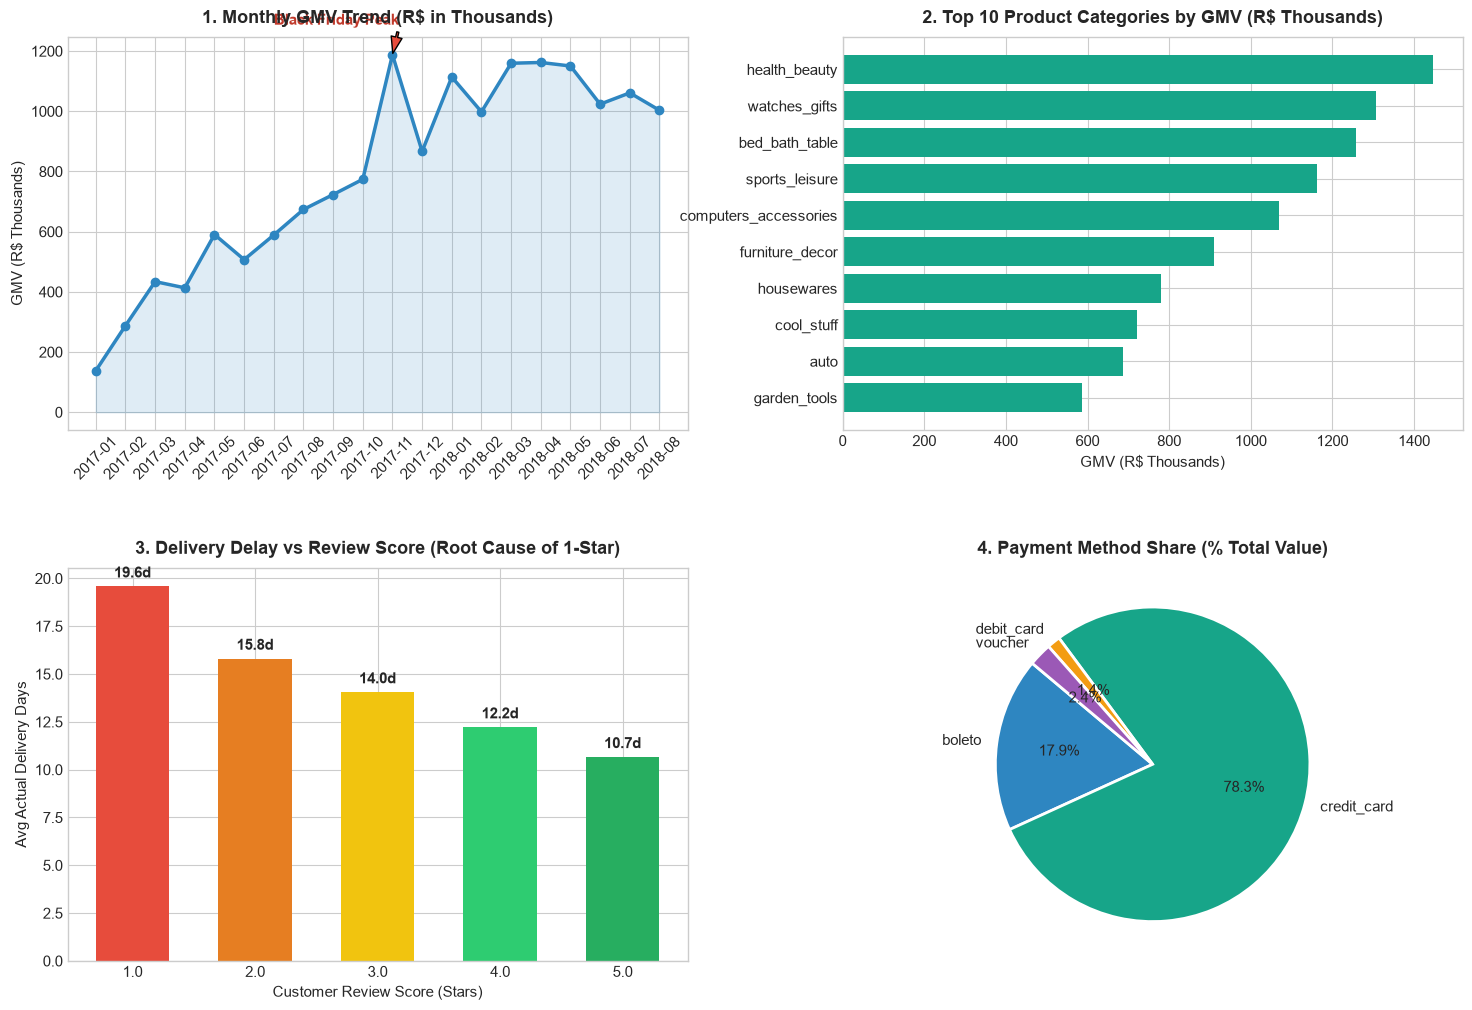

✅ EDA Visualizations successfully rendered!


In [9]:
# Create combined analysis dataframe (Orders + Items + Products + Reviews)
df_merged = order_items_clean.merge(
    orders_clean[['order_id', 'order_purchase_timestamp', 'delivery_days_actual', 'delivery_days_estimated', 'is_late_delivery']],
    on='order_id',
    how='inner'
).merge(
    products[['product_id', 'product_category_name_english']],
    on='product_id',
    how='left'
).merge(
    reviews_clean[['order_id', 'review_score']],
    on='order_id',
    how='left'
)

# Extract Year-Month for trend analysis
df_merged['year_month'] = df_merged['order_purchase_timestamp'].dt.to_period('M').astype(str)
# Filter complete operational months (Jan 2017 to Aug 2018)
trend_df = df_merged[(df_merged['year_month'] >= '2017-01') & (df_merged['year_month'] <= '2018-08')]

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

# --- Chart 1: Monthly GMV Growth Trend ---
monthly_gmv = trend_df.groupby('year_month')['total_value'].sum() / 1000 # in R$ Thousands
axes[0, 0].plot(monthly_gmv.index, monthly_gmv.values, marker='o', color='#2E86C1', linewidth=2.5)
axes[0, 0].fill_between(monthly_gmv.index, monthly_gmv.values, color='#2E86C1', alpha=0.15)
axes[0, 0].set_title('1. Monthly GMV Trend (R$ in Thousands)', fontsize=13, fontweight='bold', pad=10)
axes[0, 0].set_ylabel('GMV (R$ Thousands)')
axes[0, 0].tick_params(axis='x', rotation=45)
# Annotate Black Friday 2017 peak
if '2017-11' in monthly_gmv.index:
    axes[0, 0].annotate('Black Friday Peak', xy=('2017-11', monthly_gmv['2017-11']),
                        xytext=('2017-07', monthly_gmv['2017-11'] + 100),
                        arrowprops=dict(facecolor='#E74C3C', shrink=0.05, width=1.5, headwidth=8),
                        fontweight='bold', color='#C0392B')

# --- Chart 2: Top 10 Product Categories by GMV ---
top_cats = df_merged.groupby('product_category_name_english')['total_value'].sum().nlargest(10) / 1000
axes[0, 1].barh(top_cats.index[::-1], top_cats.values[::-1], color='#17A589')
axes[0, 1].set_title('2. Top 10 Product Categories by GMV (R$ Thousands)', fontsize=13, fontweight='bold', pad=10)
axes[0, 1].set_xlabel('GMV (R$ Thousands)')

# --- Chart 3: Avg Delivery Days by Review Score (Proof of SLA Impact!) ---
review_delay = df_merged.groupby('review_score')['delivery_days_actual'].mean()
colors = ['#E74C3C', '#E67E22', '#F1C40F', '#2ECC71', '#27AE60']
bars = axes[1, 0].bar(review_delay.index.astype(str), review_delay.values, color=colors, width=0.6)
axes[1, 0].set_title('3. Delivery Delay vs Review Score (Root Cause of 1-Star)', fontsize=13, fontweight='bold', pad=10)
axes[1, 0].set_xlabel('Customer Review Score (Stars)')
axes[1, 0].set_ylabel('Avg Actual Delivery Days')
for bar in bars:
    yval = bar.get_height()
    axes[1, 0].text(bar.get_x() + bar.get_width()/2, yval + 0.3, f"{yval:.1f}d", ha='center', va='bottom', fontweight='bold')

# --- Chart 4: Payment Method Split by Value ---
payment_split = payments_clean.groupby('payment_type')['payment_value'].sum() / 1e6
axes[1, 1].pie(payment_split, labels=payment_split.index, autopct='%1.1f%%', 
               startangle=140, colors=['#2E86C1', '#17A589', '#F39C12', '#9B59B6'],
               wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1, 1].set_title('4. Payment Method Share (% Total Value)', fontsize=13, fontweight='bold', pad=10)

plt.show()
print("✅ EDA Visualizations successfully rendered!")

In [10]:
import os

# Create output directories
OUTPUT_DIR = '../output/star_schema'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ═══════════════════════════════════════════════════════════
# 1. GENERATE DIM_DATE (Calendar Table for Time Intelligence)
# ═══════════════════════════════════════════════════════════
min_date = orders_clean['order_purchase_timestamp'].min().floor('D')
max_date = orders_clean['order_estimated_delivery_date'].max().ceil('D')

date_range = pd.date_range(start=min_date, end=max_date, freq='D')
dim_date = pd.DataFrame({'date_key': date_range.date})
dim_date['full_date'] = pd.to_datetime(dim_date['date_key'])
dim_date['year'] = dim_date['full_date'].dt.year
dim_date['quarter'] = dim_date['full_date'].dt.quarter
dim_date['month'] = dim_date['full_date'].dt.month
dim_date['month_name'] = dim_date['full_date'].dt.strftime('%B')
dim_date['year_month'] = dim_date['full_date'].dt.strftime('%Y-%m')
dim_date['week_of_year'] = dim_date['full_date'].dt.isocalendar().week
dim_date['day_of_month'] = dim_date['full_date'].dt.day
dim_date['day_name'] = dim_date['full_date'].dt.strftime('%A')
dim_date['is_weekend'] = dim_date['full_date'].dt.dayofweek.isin([5, 6]).astype(int)

# ═══════════════════════════════════════════════════════════
# 2. SHAPE DIMENSION TABLES (For BigQuery & Sheets)
# ═══════════════════════════════════════════════════════════
dim_customers = customers_clean[[
    'customer_id', 'customer_unique_id', 'customer_city', 
    'customer_state', 'customer_zip_code_prefix', 'latitude', 'longitude'
]].copy()

dim_products = products[[
    'product_id', 'product_category_name', 'product_category_name_english',
    'product_name_length', 'product_description_length', 'product_photos_qty',
    'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm',
    'product_volume_cm3'
]].copy()

dim_sellers = sellers_clean[[
    'seller_id', 'seller_city', 'seller_state', 
    'seller_zip_code_prefix', 'latitude', 'longitude'
]].copy()

# Business Benchmarks Lookup (For Google Sheets)
kpi_targets = pd.DataFrame([
    {"kpi_name": "On-Time Delivery Rate", "target_value": 0.95, "unit": "percentage", "description": "Target: >= 95% on-time"},
    {"kpi_name": "Average Review Score", "target_value": 4.00, "unit": "score", "description": "Target: >= 4.0 out of 5.0"},
    {"kpi_name": "Order Cancellation Rate", "target_value": 0.02, "unit": "percentage", "description": "Target: <= 2% canceled"},
    {"kpi_name": "Average Delivery Days", "target_value": 12.0, "unit": "days", "description": "Target: <= 12 days transit"},
    {"kpi_name": "Freight-to-Price Ratio", "target_value": 0.20, "unit": "percentage", "description": "Target: <= 20% freight burden"}
])

# ═══════════════════════════════════════════════════════════
# 3. SHAPE FACT TABLES (For Supabase PostgreSQL)
# ═══════════════════════════════════════════════════════════
fact_orders = orders_clean[[
    'order_id', 'customer_id', 'purchase_date_key', 'order_status',
    'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
    'order_delivered_customer_date', 'order_estimated_delivery_date',
    'delivery_days_actual', 'delivery_days_estimated', 'is_late_delivery'
]].copy()

# Add purchase_date_key to order_items for instant time slicing
fact_order_items = order_items_clean.merge(
    orders_clean[['order_id', 'purchase_date_key']],
    on='order_id',
    how='inner'
)[[
    'order_id', 'order_item_id', 'product_id', 'seller_id', 
    'purchase_date_key', 'price', 'freight_value', 'total_value', 'freight_to_price_ratio'
]]

fact_payments = payments_clean[[
    'order_id', 'payment_sequential', 'payment_type', 
    'payment_installments', 'payment_value'
]].copy()

fact_reviews = reviews_clean[[
    'review_id', 'order_id', 'review_score', 
    'review_creation_date', 'review_answer_timestamp'
]].copy()

# ═══════════════════════════════════════════════════════════
# 4. SAVE TO OUTPUT FOLDER AS CLEAN CSVs
# ═══════════════════════════════════════════════════════════
star_schema_tables = {
    # Dimensions
    "dim_date": dim_date,
    "dim_customers": dim_customers,
    "dim_products": dim_products,
    "dim_sellers": dim_sellers,
    "kpi_targets": kpi_targets,
    "category_translation": translations,
    # Facts
    "fact_orders": fact_orders,
    "fact_order_items": fact_order_items,
    "fact_payments": fact_payments,
    "fact_reviews": fact_reviews
}

print("💾 Exporting Star Schema tables to output/star_schema/...")
for table_name, df in star_schema_tables.items():
    file_path = os.path.join(OUTPUT_DIR, f"{table_name}.csv")
    df.to_csv(file_path, index=False)
    print(f"  ✓ {table_name:<20}: {len(df):>8,} rows saved")

print("\n🎉 Star Schema tables successfully created and exported!")

💾 Exporting Star Schema tables to output/star_schema/...
  ✓ dim_date            :      800 rows saved
  ✓ dim_customers       :   99,441 rows saved
  ✓ dim_products        :   32,951 rows saved
  ✓ dim_sellers         :    3,095 rows saved
  ✓ kpi_targets         :        5 rows saved
  ✓ category_translation:       71 rows saved
  ✓ fact_orders         :   99,441 rows saved
  ✓ fact_order_items    :  112,650 rows saved
  ✓ fact_payments       :  103,877 rows saved
  ✓ fact_reviews        :   99,224 rows saved

🎉 Star Schema tables successfully created and exported!


In [11]:
# ═══════════════════════════════════════════════════════════
# DATA QUALITY & REFERENTIAL INTEGRITY VALIDATION
# ═══════════════════════════════════════════════════════════

validation_results = []

def check_referential_integrity(child_df, child_col, parent_df, parent_col, relationship_name):
    """Check if all foreign keys in child table exist in parent table."""
    orphans = (~child_df[child_col].isin(parent_df[parent_col])).sum()
    status = "✅ PASS" if orphans == 0 else f"❌ FAIL ({orphans:,} orphans)"
    validation_results.append({
        "Check Type": "Referential Integrity",
        "Test": relationship_name,
        "Result": status,
        "Orphans / Issues": orphans
    })
    return orphans

# 1. Foreign Key Integrity Checks
print("🔍 Running Foreign Key Integrity Checks...")
check_referential_integrity(fact_orders, 'customer_id', dim_customers, 'customer_id', "fact_orders.customer_id -> dim_customers")
check_referential_integrity(fact_orders, 'purchase_date_key', dim_date, 'date_key', "fact_orders.purchase_date_key -> dim_date")
check_referential_integrity(fact_order_items, 'order_id', fact_orders, 'order_id', "fact_order_items.order_id -> fact_orders")
check_referential_integrity(fact_order_items, 'product_id', dim_products, 'product_id', "fact_order_items.product_id -> dim_products")
check_referential_integrity(fact_order_items, 'seller_id', dim_sellers, 'seller_id', "fact_order_items.seller_id -> dim_sellers")
check_referential_integrity(fact_payments, 'order_id', fact_orders, 'order_id', "fact_payments.order_id -> fact_orders")
check_referential_integrity(fact_reviews, 'order_id', fact_orders, 'order_id', "fact_reviews.order_id -> fact_orders")

# 2. Logic & Range Checks
print("🔍 Running Range & Logic Validation Checks...")
invalid_prices = (fact_order_items['price'] <= 0).sum()
validation_results.append({
    "Check Type": "Range Check", "Test": "Price > 0", 
    "Result": "✅ PASS" if invalid_prices == 0 else f"❌ FAIL ({invalid_prices})", "Orphans / Issues": invalid_prices
})

invalid_reviews = (~fact_reviews['review_score'].between(1, 5)).sum()
validation_results.append({
    "Check Type": "Range Check", "Test": "Review Score between 1 and 5", 
    "Result": "✅ PASS" if invalid_reviews == 0 else f"❌ FAIL ({invalid_reviews})", "Orphans / Issues": invalid_reviews
})

invalid_payments = (fact_payments['payment_value'] <= 0).sum()
validation_results.append({
    "Check Type": "Range Check", "Test": "Payment Value > 0", 
    "Result": "✅ PASS" if invalid_payments == 0 else f"❌ FAIL ({invalid_payments})", "Orphans / Issues": invalid_payments
})

val_df = pd.DataFrame(validation_results)

# Display report in notebook
print("\n" + "="*70)
print("📋 DATA QUALITY & INTEGRITY AUDIT RESULTS")
print("="*70)
print(val_df.to_string(index=False))

# Export to output/data_quality_report.md
report_md = f"""# 🛡️ Data Quality & Referential Integrity Audit Report

**Generated:** {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')}  
**Status:** {'ALL CHECKS PASSED ✅' if (val_df['Orphans / Issues'] == 0).all() else 'ISSUES FOUND ⚠️'}

## Integrity & Validation Summary Table

| Check Type | Relationship / Test | Result | Issue Count |
|---|---|---|---|
"""
for _, r in val_df.iterrows():
    report_md += f"| {r['Check Type']} | `{r['Test']}` | {r['Result']} | {r['Orphans / Issues']} |\n"

with open('../output/data_quality_report.md', 'w', encoding='utf-8') as f:
    f.write(report_md)

print("\n📄 Detailed report saved to: output/data_quality_report.md")

🔍 Running Foreign Key Integrity Checks...
🔍 Running Range & Logic Validation Checks...

📋 DATA QUALITY & INTEGRITY AUDIT RESULTS
           Check Type                                        Test Result  Orphans / Issues
Referential Integrity    fact_orders.customer_id -> dim_customers ✅ PASS                 0
Referential Integrity   fact_orders.purchase_date_key -> dim_date ✅ PASS                 0
Referential Integrity    fact_order_items.order_id -> fact_orders ✅ PASS                 0
Referential Integrity fact_order_items.product_id -> dim_products ✅ PASS                 0
Referential Integrity   fact_order_items.seller_id -> dim_sellers ✅ PASS                 0
Referential Integrity       fact_payments.order_id -> fact_orders ✅ PASS                 0
Referential Integrity        fact_reviews.order_id -> fact_orders ✅ PASS                 0
          Range Check                                   Price > 0 ✅ PASS                 0
          Range Check                Review Score be